In [1]:
import sys
print(sys.executable)

import os
import glob
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pathlib
import re
import pandas as pd

/Users/dubby/MyPythonCoding/conda_envs/hw4/bin/python3.13


In [2]:
# 概览

data_dir = "kaggle_3m"
patient_dirs = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
print(f"共有 {len(patient_dirs)} 个病人")
sample_patient = patient_dirs[0]
sample_files = glob.glob(os.path.join(data_dir, sample_patient, "*.tif"))
print(f"示例病人 {sample_patient} 下有 {len(sample_files)} 张图像")
# Note on File. Refer to the archived source for the detailed original comment.
print(sample_files[:5])

共有 110 个病人
示例病人 TCGA_CS_6667_20011105 下有 40 张图像
['kaggle_3m/TCGA_CS_6667_20011105/TCGA_CS_6667_20011105_8_mask.tif', 'kaggle_3m/TCGA_CS_6667_20011105/TCGA_CS_6667_20011105_9_mask.tif', 'kaggle_3m/TCGA_CS_6667_20011105/TCGA_CS_6667_20011105_2_mask.tif', 'kaggle_3m/TCGA_CS_6667_20011105/TCGA_CS_6667_20011105_3_mask.tif', 'kaggle_3m/TCGA_CS_6667_20011105/TCGA_CS_6667_20011105_20_mask.tif']


### Experiment / Results / Comparative Experiment

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


注：baseline 缺少文件，使用手动设置的 DSC = 0.908689
  汇总结果已保存到 summary_results.csv
  实验名称列表: ['baseline (maxpool)', 'pixelshuffle_adam', 'adamw', 'pixelshuffle_adamw', 'up_bilinear', 'DiceBCE', 'BCE_Dice_EqualW', 'BCE_Dice_BCEMore', 'amp', 'elastic', 'BCE_Dice_DiceMore', 'down_stride', 'focal', 'ultimate']


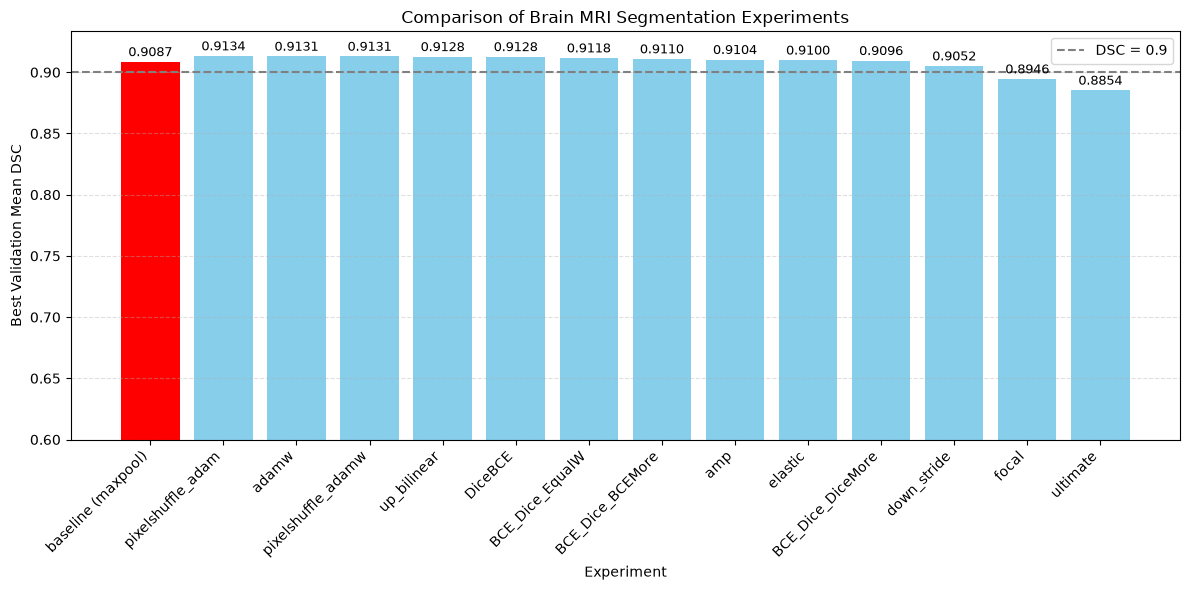

In [3]:
ckpt_root = pathlib.Path("./ckpt")

def extract_experiment_name(dirname):
    """去掉目录名开头的时间戳，返回纯实验名"""
    match = re.match(r'^\d{6}-\d{6}\s+(.*)$', dirname)
    if match:
        return match.group(1).strip()
    return dirname.strip()

BASELINE_DSC =  0.908689 

rows = []

for exp_dir in sorted(ckpt_root.iterdir()):
    if not exp_dir.is_dir():
        continue
    # 只处理以时间戳开头的目录（避免处理 samples、汇总图等）
    if not re.match(r'^\d{6}-\d{6}\s+', exp_dir.name):
        continue

    short_name = extract_experiment_name(exp_dir.name)
    if short_name == "baseline":
        short_name = "baseline (maxpool)"

    config_path = exp_dir / "config.json"
    hist_path = exp_dir / "losses_dsc_values.json"

    # Note on File. Refer to the archived source for the detailed original comment.
    if short_name == "baseline (maxpool)" and (not config_path.exists() or not hist_path.exists()):
        print(f"注：baseline 缺少文件，使用手动设置的 DSC = {BASELINE_DSC}")
        rows.append({
            "experiment": "baseline (maxpool)",
            "best_val_dsc": BASELINE_DSC,
            "best_epoch": None,
            "network": None,
            "downsample": None,
            "upsample": None,
            "loss": None,
            "optimizer": None,
            "lr": None,
            "weight_decay": None,
            "scheduler": None,
            "amp": None,
            "elastic": None,
            "epochs": None,
            "batch_size": None,
            "final_val_loss": None,
        })
        continue  # 跳过后续读取

    if not config_path.exists() or not hist_path.exists():
        print(f" 跳过 {exp_dir.name}：缺少 config.json 或 losses_dsc_values.json")
        continue

    # Note on Load. Refer to the archived source for the detailed original comment.
    with open(config_path, "r") as f:
        cfg = json.load(f)
    with open(hist_path, "r") as f:
        hist = json.load(f)

    dsc_epochs = hist["dsc_per_epoch_per_patient"]
    mean_dsc = [float(np.mean(x)) for x in dsc_epochs]
    best_epoch = int(np.argmax(mean_dsc))
    best_dsc = float(np.max(mean_dsc))

    val_loss_epochs = hist.get("loss_per_epoch_per_patient", [])
    if val_loss_epochs:
        mean_val_loss = [float(np.mean(x)) for x in val_loss_epochs]
        final_val_loss = float(mean_val_loss[-1])
    else:
        final_val_loss = None

    rows.append({
        "experiment": short_name,
        "best_val_dsc": best_dsc,
        "best_epoch": best_epoch,
        "network": cfg.get("network"),
        "downsample": cfg.get("downsample"),
        "upsample": cfg.get("upsample"),
        "loss": cfg.get("loss"),
        "optimizer": cfg.get("optimizer"),
        "lr": cfg.get("lr"),
        "weight_decay": cfg.get("weight_decay"),
        "scheduler": cfg.get("scheduler"),
        "amp": cfg.get("amp"),
        "elastic": cfg.get("elastic"),
        "epochs": cfg.get("epochs"),
        "batch_size": cfg.get("batch_size"),
        "final_val_loss": final_val_loss,
    })

# 构建 DataFrame
df = pd.DataFrame(rows)
baseline_mask = df["experiment"] == "baseline (maxpool)"
baseline_df = df[baseline_mask]
others_df = df[~baseline_mask].sort_values("best_val_dsc", ascending=False)
df_final = pd.concat([baseline_df, others_df], ignore_index=True)

# Note on Save. Refer to the archived source for the detailed original comment.
df_final.to_csv("summary_results.csv", index=False)
print("  汇总结果已保存到 summary_results.csv")
print("  实验名称列表:", df_final["experiment"].tolist())

# Note on Plot. Refer to the archived source for the detailed original comment.
plt.figure(figsize=(12, 6))
colors = ['red' if exp.strip() == "baseline (maxpool)" else 'skyblue' for exp in df_final["experiment"]]
bars = plt.bar(df_final["experiment"], df_final["best_val_dsc"], color=colors)

ymax = max(df_final["best_val_dsc"]) + 0.02
plt.ylim(0.6, ymax)
plt.axhline(y=0.9, color='gray', linestyle='--', linewidth=1.5, label='DSC = 0.9')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.002,
             f'{height:.4f}',
             ha='center', va='bottom', fontsize=9)

plt.xlabel("Experiment")
plt.ylabel("Best Validation Mean DSC")
plt.title("Comparison of Brain MRI Segmentation Experiments")
plt.xticks(rotation=45, ha='right')
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("best_dsc_summary.png", dpi=200)
plt.show()

### Training

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


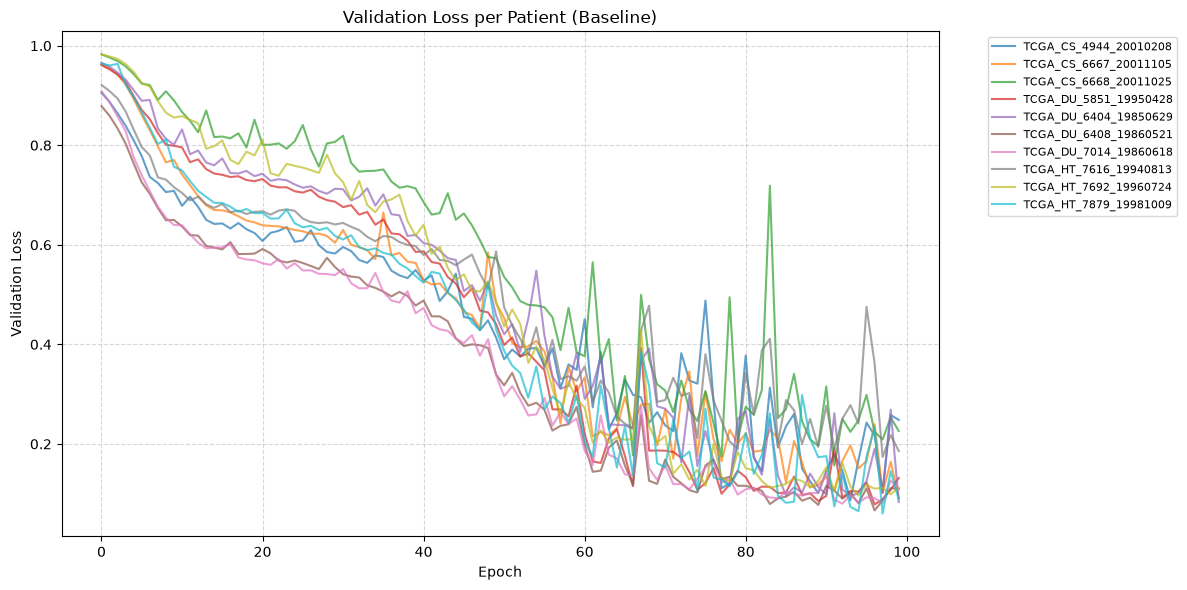

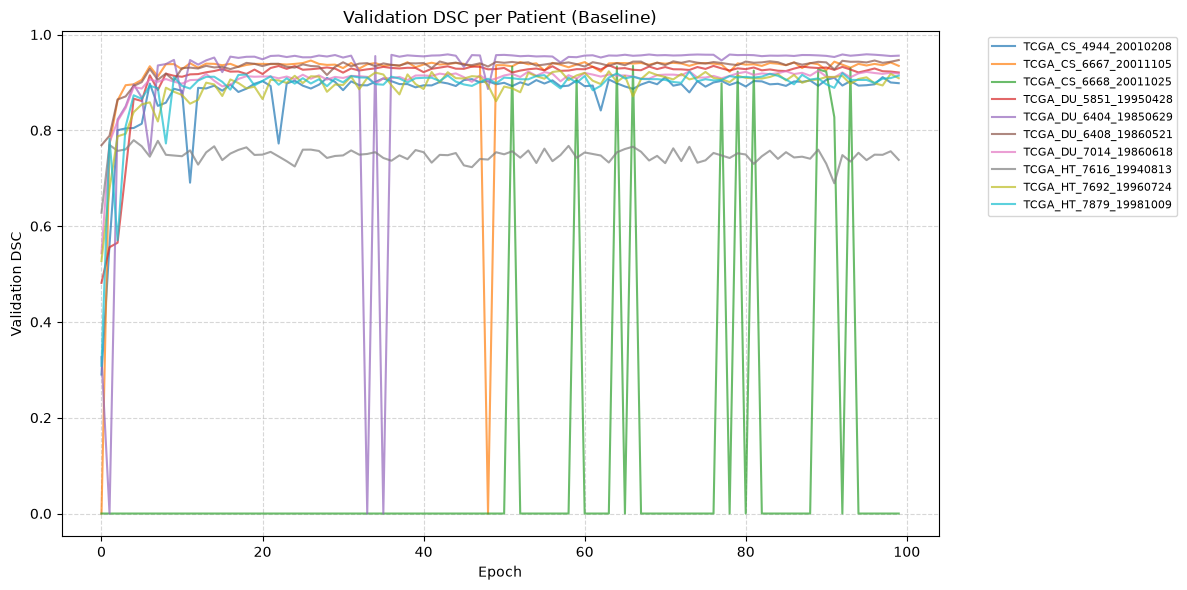

未找到 train_loss_per_epoch，跳过图3


In [9]:
# Note on Load. Refer to the archived source for the detailed original comment.
json_path = Path("./ckpt/260703-133000 baseline/losses_dsc_values.json") 
with open(json_path, "r") as f:
    data = json.load(f)

patient_names = data["patient_names"]
loss_per_epoch = data["loss_per_epoch_per_patient"]   # list of lists: [epoch][patient]
dsc_per_epoch  = data["dsc_per_epoch_per_patient"]
train_losses   = data.get("train_loss_per_epoch", [])  

epochs = len(loss_per_epoch)

# ========== 图1: 每个病人的 Loss 曲线 ==========
plt.figure(figsize=(12, 6))
for i, name in enumerate(patient_names):
    patient_losses = [epoch_losses[i] for epoch_losses in loss_per_epoch]
    plt.plot(range(epochs), patient_losses, label=name, alpha=0.7)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss per Patient (Baseline)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("loss_per_patient.png", dpi=150)
plt.show()

# ========== 图2: 每个病人的 DSC 曲线 ==========
plt.figure(figsize=(12, 6))
for i, name in enumerate(patient_names):
    patient_dsc = [epoch_dscs[i] for epoch_dscs in dsc_per_epoch]
    plt.plot(range(epochs), patient_dsc, label=name, alpha=0.7)

plt.xlabel("Epoch")
plt.ylabel("Validation DSC")
plt.title("Validation DSC per Patient (Baseline)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("dsc_per_patient.png", dpi=150)
plt.show()

# Note on Training, Validation. Refer to the archived source for the detailed original comment.
if train_losses:
    # Note on Validation, Compute. Refer to the archived source for the detailed original comment.
    mean_val_loss = [np.mean(epoch_losses) for epoch_losses in loss_per_epoch]
    
    plt.figure(figsize=(12, 6))  # 与图1、图2一致
    plt.plot(range(epochs), train_losses, label='Train Loss', 
             color='blue', linestyle='-', linewidth=1.5, alpha=0.8)
    plt.plot(range(epochs), mean_val_loss, label='Mean Validation Loss', 
             color='red', linestyle='--', linewidth=1.5, alpha=0.8)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend(loc='best')  # 自动选择最佳位置
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("train_val_loss.png", dpi=150)
    plt.show()
else:
    print("未找到 train_loss_per_epoch，跳过图3") # baseline的代码没有记录train_loss_per_epoch

### Results and Analysis / Results / Analysis

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [3]:
import os
import glob
import numpy as np
from skimage.io import imread
import pandas as pd

data_dir = "kaggle_3m"

rows = []
for patient in sorted(os.listdir(data_dir)):
    patient_dir = os.path.join(data_dir, patient)
    if not os.path.isdir(patient_dir):
        continue

    mask_files = sorted(glob.glob(os.path.join(patient_dir, "*_mask.tif")))
    total_slices = len(mask_files)
    positive_slices = 0
    total_tumor_pixels = 0

    for mf in mask_files:
        mask = imread(mf)
        tumor_pixels = np.sum(mask > 0)
        total_tumor_pixels += tumor_pixels
        if tumor_pixels > 0:
            positive_slices += 1

    rows.append({
        "patient": patient,
        "total_slices": total_slices,
        "positive_slices": positive_slices,
        "positive_slice_ratio": positive_slices / total_slices if total_slices else 0,
        "total_tumor_pixels": total_tumor_pixels,
        "avg_tumor_pixels_per_slice": total_tumor_pixels / total_slices if total_slices else 0,
    })

df_patient = pd.DataFrame(rows)
df_patient.sort_values("positive_slice_ratio").head(20)

,patient,total_slices,positive_slices,positive_slice_ratio,total_tumor_pixels,avg_tumor_pixels_per_slice
48,TCGA_DU_8163_19961119,37,5,0.135135,4443,120.081081
50,TCGA_DU_8165_19970205,36,5,0.138889,1870,51.944444
82,TCGA_HT_7680_19970202,21,3,0.142857,2059,98.047619
71,TCGA_FG_7643_20021104,48,7,0.145833,5087,105.979167
29,TCGA_DU_6405_19851005,60,9,0.150000,4822,80.366667
5,TCGA_CS_5395_19981004,20,3,0.150000,2356,117.800000
9,TCGA_CS_6188_20010812,24,4,0.166667,2068,86.166667
60,TCGA_DU_A5TY_19970709,36,7,0.194444,4701,130.583333
19,TCGA_DU_5853_19950823,36,7,0.194444,6322,175.611111
66,TCGA_FG_6690_20020226,60,12,0.200000,7524,125.400000


In [4]:
df_patient[df_patient["patient"].str.contains("6668")]

,patient,total_slices,positive_slices,positive_slice_ratio,total_tumor_pixels,avg_tumor_pixels_per_slice
14,TCGA_CS_6668_20011025,28,7,0.25,7223,257.964286


### Model / Training / Prediction

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Training

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


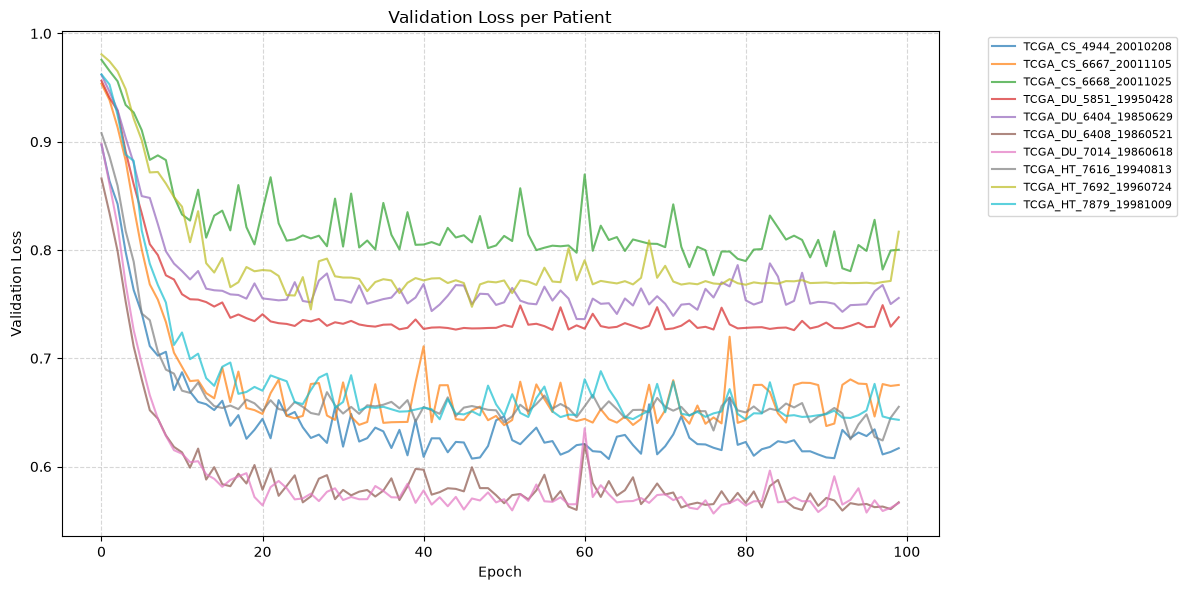

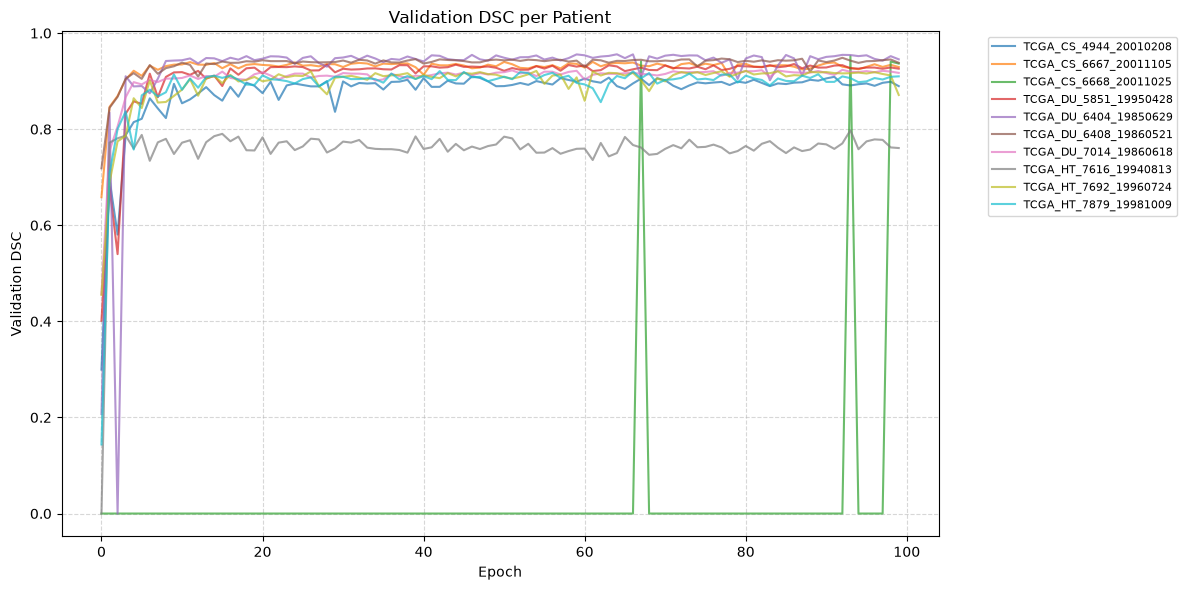

<Figure size 1200x600 with 1 Axes>

In [7]:
# Note on Load. Refer to the archived source for the detailed original comment.
json_path = Path("./ckpt/260708-141256 pixelshuffle_adam/losses_dsc_values.json") 
with open(json_path, "r") as f:
    data = json.load(f)

patient_names = data["patient_names"]
loss_per_epoch = data["loss_per_epoch_per_patient"]   # [epoch][patient]
dsc_per_epoch  = data["dsc_per_epoch_per_patient"]
train_losses   = data.get("train_loss_per_epoch", [])  

epochs = len(loss_per_epoch)

# Note on Validation. Refer to the archived source for the detailed original comment.
plt.figure(figsize=(12, 6))
for i, name in enumerate(patient_names):
    patient_losses = [epoch_losses[i] for epoch_losses in loss_per_epoch]
    plt.plot(range(epochs), patient_losses, label=name, alpha=0.7)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss per Patient")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("loss_per_patient.png", dpi=150)
plt.show()

# ========== 图2: 每个病人的 DSC 曲线 ==========
plt.figure(figsize=(12, 6))
for i, name in enumerate(patient_names):
    patient_dsc = [epoch_dscs[i] for epoch_dscs in dsc_per_epoch]
    plt.plot(range(epochs), patient_dsc, label=name, alpha=0.7)

plt.xlabel("Epoch")
plt.ylabel("Validation DSC")
plt.title("Validation DSC per Patient")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("dsc_per_patient.png", dpi=150)
plt.show()

# Note on Training, Validation. Refer to the archived source for the detailed original comment.
if train_losses:
    # Note on Validation, Compute. Refer to the archived source for the detailed original comment.
    mean_val_loss = [np.mean(epoch_losses) for epoch_losses in loss_per_epoch]
    
    plt.figure(figsize=(12, 6))  # 与图1、图2一致
    plt.plot(range(epochs), train_losses, label='Train Loss', 
             color='blue', linestyle='-', linewidth=1.5, alpha=0.8)
    plt.plot(range(epochs), mean_val_loss, label='Mean Validation Loss', 
             color='red', linestyle='--', linewidth=1.5, alpha=0.8)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend(loc='best')  # 自动选择最佳位置
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("train_val_loss.png", dpi=150)
    plt.show()
else:
    print("未找到 train_loss_per_epoch，跳过图3")

### Model / Segmentation

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [1]:
import os
import pathlib
import tqdm
import numpy as np
import torch
from matplotlib import pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg
from skimage.io import imsave
from torch.utils.data import DataLoader
import PIL.Image
import IPython.display as ipd

from dataset import BrainSegmentationDataset
from unet import UNet
from utils import dsc, gray2rgb, outline, largest_connected_component

In [8]:
# Note on Parameters, Input. Refer to the archived source for the detailed original comment.
# Note on Dataset, Path, Data. Refer to the archived source for the detailed original comment.
# Note on Model, Training, Parameters, File. Refer to the archived source for the detailed original comment.
data_root_dir = './kaggle_3m'
ckpt_path     = './ckpt/260703-133000 baseline/unet.pt'

batch_size    = 32

# 屏蔽 CUDA（可选，防止意外）
os.environ["CUDA_VISIBLE_DEVICES"] = ""

# Note on Settings. Refer to the archived source for the detailed original comment.
if torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

Using device: mps


In [10]:
dataset = BrainSegmentationDataset(images_dir=data_root_dir, is_train=False,)
loader = DataLoader(dataset, batch_size=batch_size, drop_last=False, num_workers=0)

unet = UNet(in_channels=BrainSegmentationDataset.in_channels, out_channels=BrainSegmentationDataset.out_channels)
state_dict = torch.load(ckpt_path, map_location='cpu')   # 先加载到 CPU
unet.load_state_dict(state_dict)
unet.eval()
unet.to(device)

x_list = []
y_pred_list = []
y_true_list = []

with torch.no_grad():
    for i, (x, y_true, g_inv) in enumerate(tqdm.tqdm(loader, desc='Inference')):
        x      = x     .to(device)
        y_true = y_true.to(device)

        y_pred = unet(x)

        # Note on Note. Refer to the archived source for the detailed original comment.
        x_np      = x     .detach().cpu().numpy()
        y_pred_np = y_pred.detach().cpu().numpy()
        y_true_np = y_true.detach().cpu().numpy()

        y_pred_list.extend([y_pred_np[s] for s in range(y_pred_np.shape[0])])
        y_true_list.extend([y_true_np[s] for s in range(y_true_np.shape[0])])
        x_list     .extend([x_np     [s] for s in range(x_np     .shape[0])])

# Note on Data. Refer to the archived source for the detailed original comment.
volumes = {}
num_slices = np.bincount([p[0] for p in dataset.patient_slice_index])
index = 0
for p in range(len(num_slices)):
    volume_in = np.array(x_list[index : index + num_slices[p]])
    volume_pred = np.round(np.array(y_pred_list[index : index + num_slices[p]])).astype(int)
    volume_pred = largest_connected_component(volume_pred)
    volume_true = np.array(y_true_list[index : index + num_slices[p]])
    volumes[dataset.patients[p]] = (volume_in, volume_pred, volume_true)
    index += num_slices[p]


Reading 355 images from validation set ...


Inference: 100%|███████████████████████████████| 12/12 [00:04<00:00,  2.80it/s]


In [11]:
samples_dir = pathlib.Path(ckpt_path).parent / 'samples'
samples_dir.mkdir(parents=True, exist_ok=True)
print(f'Saving samples to: {samples_dir}')

for p in tqdm.tqdm(volumes):
    x      = volumes[p][0]
    y_pred = volumes[p][1]
    y_true = volumes[p][2]
    for s in range(x.shape[0]):
        image = gray2rgb(x[s, 1])  # channel 1 is for FLAIR
        image = outline(image, y_pred[s, 0], color=[255, 0, 0])
        image = outline(image, y_true[s, 0], color=[0, 255, 0])
        filename = '{}-{}.png'.format(p, str(s).zfill(2))
        filepath = pathlib.Path(samples_dir, filename)
        imsave(filepath, image)


Saving samples to: ckpt/260703-133000 baseline/samples


 50%|█████████████████████▌                     | 5/10 [00:01<00:01,  4.37it/s]/Users/dubby/MyPythonCoding/conda_envs/hw4/lib/python3.13/site-packages/skimage/_shared/utils.py:386: UserWarning: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验4-脑部MRI图像分割/brain-seg/ckpt/260703-133000 baseline/samples/TCGA_DU_6408_19860521-55.png is a low contrast image
  return func(*args, **kwargs)
100%|██████████████████████████████████████████| 10/10 [00:02<00:00,  3.57it/s]


### Model

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [9]:
# Note on Model, Define, Use. Refer to the archived source for the detailed original comment.
from unet_exp import UNet                     
from dataset import BrainSegmentationDataset
from utils import gray2rgb, outline

# ---------- 配置 ----------
data_root_dir = './kaggle_3m'                 # 验证集路径
ckpt_root = pathlib.Path('./ckpt')            # 所有实验的根目录
output_dir = pathlib.Path('./ckpt/best_samples')
output_dir.mkdir(exist_ok=True)

# Note on Experiment, Results, Summary, Load. Refer to the archived source for the detailed original comment.
df = pd.read_csv("summary_results.csv")
# 按 best_val_dsc 降序排序，取第一行
best_row = df.loc[df["best_val_dsc"].idxmax()]
best_exp_name = best_row["experiment"]
best_dsc = best_row["best_val_dsc"]
print(f"-- 最佳模型（非 baseline）: {best_exp_name}, DSC = {best_dsc:.4f}")

# Note on Experiment, Load. Refer to the archived source for the detailed original comment.
# 构造正则：前后不能是字母或数字（避免匹配到 adamw 等变体）
pattern = re.compile(r'(?<![a-zA-Z0-9])' + re.escape(best_exp_name) + r'(?![a-zA-Z0-9])')
matched_dirs = [
    d for d in ckpt_root.iterdir() 
    if d.is_dir() and pattern.search(d.name)
]

if not matched_dirs:
    raise FileNotFoundError(f"找不到包含 '{best_exp_name}' 的实验文件夹")
exp_dir = matched_dirs[0]   # 此时只会匹配到 pixelshuffle_adam（带任意前缀/后缀，只要前后是分隔符）
print(f"实际实验文件夹: {exp_dir.name}")

config_path = exp_dir / "config.json"
with open(config_path, 'r') as f:
    config = json.load(f)

downsample_mode = config.get('downsample', 'maxpool') 
upsample_mode   = config.get('upsample', 'pixelshuffle')
print(f"downsample: {downsample_mode}, upsample: {upsample_mode}")

# Note on Model, Load. Refer to the archived source for the detailed original comment.
ckpt_path = exp_dir / "unet.pt"
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

dataset = BrainSegmentationDataset(images_dir=data_root_dir, is_train=False)
loader = DataLoader(dataset, batch_size=batch_size, drop_last=False, num_workers=0)

# Note on Model, Create, Parameters. Refer to the archived source for the detailed original comment.
unet = UNet(
    in_channels=BrainSegmentationDataset.in_channels,
    out_channels=BrainSegmentationDataset.out_channels,
    downsample_mode=downsample_mode,
    upsample_mode=upsample_mode
)

state_dict = torch.load(ckpt_path, map_location='cpu') # 先加载到 CPU
unet.load_state_dict(state_dict)
unet.eval()
unet.to(device)

# Note on Generate. Refer to the archived source for the detailed original comment.
x_list = []
y_pred_list = []
y_true_list = []

with torch.no_grad():
    for i, (x, y_true, g_inv) in enumerate(tqdm.tqdm(loader, desc='Inference')):
        x      = x     .to(device)
        y_true = y_true.to(device)

        y_pred = unet(x)

        # 先 .cpu() 再 .numpy()， MPS 张量不能直接转 numpy
        x_np      = x     .detach().cpu().numpy()
        y_pred_np = y_pred.detach().cpu().numpy()
        y_true_np = y_true.detach().cpu().numpy()

        y_pred_list.extend([y_pred_np[s] for s in range(y_pred_np.shape[0])])
        y_true_list.extend([y_true_np[s] for s in range(y_true_np.shape[0])])
        x_list     .extend([x_np     [s] for s in range(x_np     .shape[0])])

# 5. 后处理（按病人重建体积）
volumes = {}
num_slices = np.bincount([p[0] for p in dataset.patient_slice_index])
index = 0
for p in range(len(num_slices)):
    volume_in = np.array(x_list[index : index + num_slices[p]])
    volume_pred = np.round(np.array(y_pred_list[index : index + num_slices[p]])).astype(int)
    volume_pred = largest_connected_component(volume_pred)   # 现在已导入
    volume_true = np.array(y_true_list[index : index + num_slices[p]])
    volumes[dataset.patients[p]] = (volume_in, volume_pred, volume_true)
    index += num_slices[p]

-- 最佳模型（非 baseline）: pixelshuffle_adam, DSC = 0.9134
实际实验文件夹: 260708-141256 pixelshuffle_adam
downsample: maxpool, upsample: pixelshuffle
Using device: mps
Reading 355 images from validation set ...


Inference: 100%|███████████████████████████████| 12/12 [00:04<00:00,  2.68it/s]


In [10]:
# Note on Save, Segmentation. Refer to the archived source for the detailed original comment.
samples_dir = pathlib.Path(ckpt_path).parent / 'samples'
samples_dir.mkdir(parents=True, exist_ok=True)
print(f'Saving samples to: {samples_dir}')

for p in tqdm.tqdm(volumes, desc='Saving images'):
    x = volumes[p][0]
    y_pred = volumes[p][1]
    y_true = volumes[p][2]
    for s in range(x.shape[0]):
        image = gray2rgb(x[s, 1])  # FLAIR 通道
        image = outline(image, y_pred[s, 0], color=[255, 0, 0])   # 红色预测
        image = outline(image, y_true[s, 0], color=[0, 255, 0])   # 绿色真实
        filename = f'{p}-{s:02d}.png'
        filepath = samples_dir / filename
        imsave(filepath, image)

print("-- 最佳模型推理完成！")

Saving samples to: ckpt/260708-141256 pixelshuffle_adam/samples


Saving images:  50%|██████████████              | 5/10 [00:01<00:01,  4.47it/s]/Users/dubby/MyPythonCoding/conda_envs/hw4/lib/python3.13/site-packages/skimage/_shared/utils.py:386: UserWarning: /Users/dubby/Desktop/驭风计划/深度学习/作业/实验4-脑部MRI图像分割/brain-seg/ckpt/260708-141256 pixelshuffle_adam/samples/TCGA_DU_6408_19860521-55.png is a low contrast image
  return func(*args, **kwargs)
Saving images: 100%|███████████████████████████| 10/10 [00:02<00:00,  3.58it/s]

-- 最佳模型推理完成！


### Segmentation

This cell documents the brain mri image segmentation experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [2]:
from PIL import Image
from collections import defaultdict

# Note on Path. Refer to the archived source for the detailed original comment.
baseline_dir = pathlib.Path("./ckpt/260703-133000 baseline/samples")
best_dir = pathlib.Path("./ckpt/260708-141256 pixelshuffle_adam/samples")

# Note on File. Refer to the archived source for the detailed original comment.
baseline_files = {f.name for f in baseline_dir.glob("*.png")}
best_files = {f.name for f in best_dir.glob("*.png")}
common_files = baseline_files & best_files

# Note on File. Refer to the archived source for the detailed original comment.
patient_layers = defaultdict(list)
for fname in sorted(common_files):
    parts = fname.rsplit('-', 1)
    if len(parts) != 2:
        continue
    patient = parts[0]
    layer_str = parts[1].replace('.png', '')
    if not layer_str.isdigit():
        continue
    layer = int(layer_str)
    patient_layers[patient].append((layer, fname))

# 只保留至少有 4 个切片的病人，取前 3 个
patients = [p for p in patient_layers if len(patient_layers[p]) >= 4]
patients = sorted(patients)[:3]

if not patients:
    raise ValueError("没有找到至少有 4 个切片的病人，请检查 samples 文件夹")

# Note on Generate. Refer to the archived source for the detailed original comment.
for patient in patients:
    # 获取该病人所有层号并排序
    sorted_layers = sorted(patient_layers[patient], key=lambda x: x[0])
    total = len(sorted_layers)
    # 取中间连续的 4 层（如果总层数为偶数，偏向中间偏左）
    mid_start = (total - 4) // 2
    layers = sorted_layers[mid_start:mid_start + 4]

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    fig.suptitle(f"Patient: {patient}  (Baseline vs Best) - Middle 4 slices", fontsize=14)

    for row, model_dir, model_name in zip(
        [0, 1],
        [baseline_dir, best_dir],
        ["Baseline", "Best"]
    ):
        for col, (layer, fname) in enumerate(layers):
            img = Image.open(model_dir / fname)
            axes[row, col].imshow(img)
            axes[row, col].axis('off')
            axes[row, col].set_title(f"Layer {layer}", fontsize=9)

    plt.tight_layout()
    save_path = f"comparison_{patient}_middle.png"
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f" 已保存: {save_path}")

<Figure size 1200x600 with 8 Axes>

 已保存: comparison_TCGA_CS_4944_20010208_middle.png


<Figure size 1200x600 with 8 Axes>

 已保存: comparison_TCGA_CS_6667_20011105_middle.png


<Figure size 1200x600 with 8 Axes>

 已保存: comparison_TCGA_CS_6668_20011025_middle.png
